# Phase 4: burned-in text

OCR (EasyOCR, GPU 0) on X-ray, mammography and ultrasound images and screened CT/MR/PET slices; only lines that match
the fingerprint, a label word, a date or (on X-rays) initials are hidden. Tested on a synthetic benchmark with known
boxes and on the 35 burned-in checks of MIDI-B.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import json
import time
import shutil
import pickle
import hashlib
from multiprocessing import Pool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
import torch

from fpdeid import paths
from fpdeid import engine
from fpdeid import fingerprint
from fpdeid import burnin
from fpdeid import pixels
from fpdeid import pixel_eval
from fpdeid import scoring
from fpdeid import validity

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

phase_results = os.path.join(paths.RESULTS, "phase4")
os.makedirs(phase_results, exist_ok=True)
synthetic_dir = os.path.join(paths.DATA, "synthetic_burnin")

print("torch", torch.__version__, "| GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0))

file_table = pd.read_csv(os.path.join(paths.DERIVED, "validation_file_table.csv"), dtype=str)
all_files = file_table["path"].tolist()
patient_of = dict(zip(file_table["path"], file_table["patient_id"]))
modality_of = dict(zip(file_table["path"], file_table["modality"]))
series_of = dict(zip(file_table["path"], file_table["series_uid"]))

torch 2.7.1+cu126 | GPU: True NVIDIA RTX 6000 Ada Generation


In [2]:
# the Phase 3 fingerprints (same as in the header cleaning)
policy_path = os.path.join(paths.CONFIGS, "policy.yaml")
settings = engine.Policy(policy_path, paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)
fingerprints, common_words = fingerprint.build_all(all_files, workers=16, common_share=settings.common_word_share,
                                                   use_site=settings.site_level)
print("fingerprints:", len(fingerprints))

fingerprints: 216


## 1. The real burned-in text in MIDI-B (35 checks)

In [3]:
checks_table = pd.read_csv(os.path.join(paths.DERIVED, "validation_pixel_checks.csv"))
uid_to_path = dict(zip(file_table["sop_uid"], file_table["path"]))
checks_table["path"] = checks_table["sop"].map(uid_to_path)

rows = []
for _, check in checks_table.iterrows():
    ds, array, photometric = pixels.load_pixels(check["path"])
    frame = pixels.first_frame(ds, array)
    found = pixels.ocr_image(frame)
    fp = fingerprints.get(patient_of[check["path"]])
    boxes, decisions = pixels.boxes_for_method(found, "fpdeid", fp, check["modality"], set(),
                                               frame.shape[0], frame.shape[1])
    for decision in decisions:
        rows.append({"modality": check["modality"], "key text": check["text"], "ocr line": decision["text"],
                     "confidence": decision["confidence"], "hide": decision["hide"], "reason": decision["reason"]})
real_table = pd.DataFrame(rows)
real_table.to_csv(os.path.join(phase_results, "real_midi_b_ocr.csv"), index=False)
real_table.head(40)

,modality,key text,ocr line,confidence,hide,reason
0,DX,JT,PORTABLE,1.000,False,radiology marker / numbers
1,DX,JT,L,1.000,False,radiology marker / numbers
2,DX,JT,UPRIGHT,0.826,False,radiology marker / numbers
3,DX,JT,JT,0.995,True,short code that looks like initials
4,CR,JONES ERIN [F] 01.12.2019 / DOB: 11.12.1937,JONES ERIN [F] 01.12.2019,0.977,True,name (PatientName)
5,CR,JONES ERIN [F] 01.12.2019 / DOB: 11.12.1937,D,1.000,False,no identifier found
6,CR,JONES ERIN [F] 01.12.2019 / DOB: 11.12.1937,DOB: 11.12.1937,0.822,True,date (PatientBirthDate)
7,MG,BELL AUSTIN [U] 02.29.2012 / DOB: 01.24.1964,ELL AUSTIN [U] 02.29.2012,0.981,True,name (PatientName)
8,MG,BELL AUSTIN [U] 02.29.2012 / DOB: 01.24.1964,DOB: 01.24.1964,0.898,True,date (PatientBirthDate)
9,MG,BELL AUSTIN [U] 02.29.2012 / DOB: 01.24.1964,8 2 9,0.175,False,radiology marker / numbers


## 2. Build the synthetic benchmark

In [4]:
single_frame = file_table[(file_table["frames"].fillna("1").astype(float) <= 1)]
projection = single_frame[single_frame["modality"].isin(["CR", "DX", "MG", "US"])]
rng = np.random.default_rng(4)
cross = single_frame[single_frame["modality"].isin(["CT", "MR", "PT"])]
cross_sample = cross.iloc[rng.choice(len(cross), size=200, replace=False)]
sources = pd.concat([projection, cross_sample])
print("source images:", len(sources), sources["modality"].value_counts().to_dict())

shutil.rmtree(synthetic_dir, ignore_errors=True)
jobs = []
for i, path in enumerate(sources["path"]):
    output = os.path.join(synthetic_dir, "images", str(i).zfill(5) + ".dcm")
    jobs.append((path, output, i))
with Pool(16) as pool:
    per_image = pool.map(burnin.make_one, jobs)

labels = []
for image_labels in per_image:
    labels.extend(image_labels)
label_table = pd.DataFrame(labels)
print("images:", label_table["file"].nunique(), "| text boxes:", len(label_table),
      "| PHI:", int(label_table["phi"].sum()), "| harmless:", int((~label_table["phi"]).sum()))
burnin.save_labels(labels, os.path.join(synthetic_dir, "labels.json"))

source images: 414 {'US': 143, 'PT': 133, 'CT': 38, 'DX': 34, 'MR': 29, 'CR': 26, 'MG': 11}


images: 400 | text boxes: 1647 | PHI: 919 | harmless: 728


In [5]:
# split by patient: 70% tune, 30% test (a patient is never in both)
def split_of(patient):
    number = int(hashlib.md5(patient.encode()).hexdigest()[:8], 16)
    return "test" if number % 10 < 3 else "tune"


label_table["split"] = label_table["patient"].map(split_of)
label_table.groupby(["split", "kind"]).size().unstack(fill_value=0)

kind,date,harmless,id,institution,name
split,,,,,
test,73,207,65,31,101
tune,172,521,190,22,265


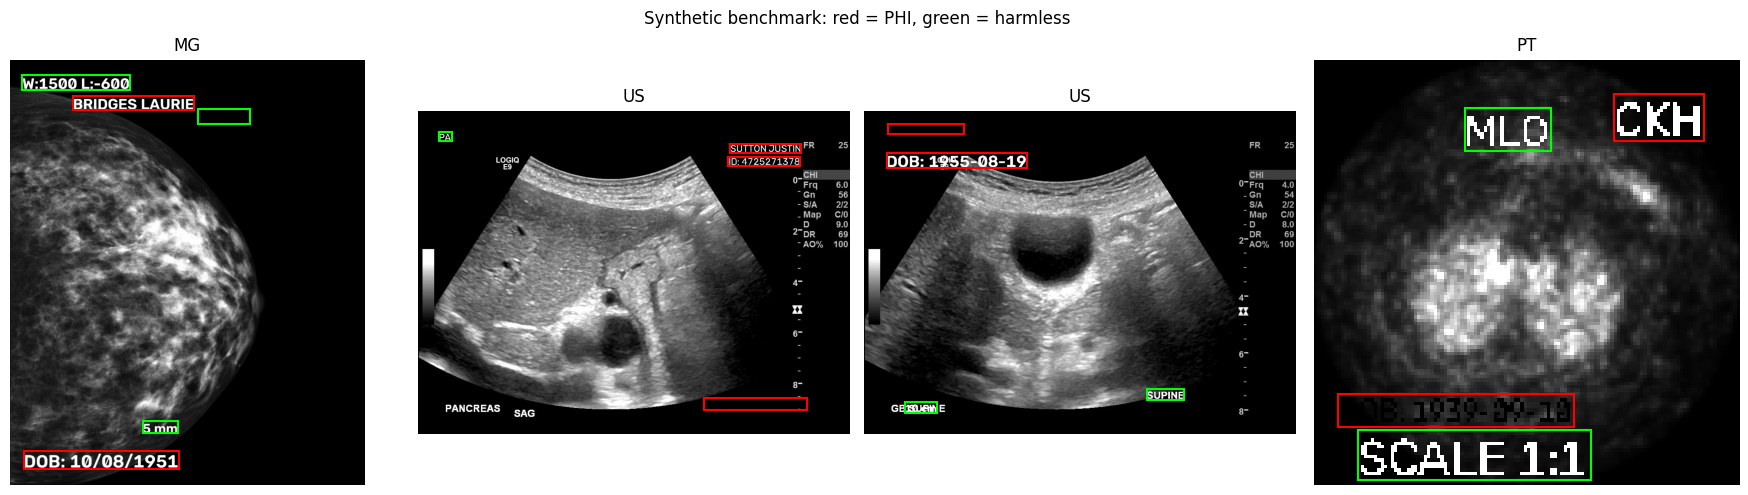

In [6]:
# show a few synthetic images
examples = label_table["file"].drop_duplicates().iloc[[0, 40, 120, 300]]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, path in zip(axes, examples):
    ds = pydicom.dcmread(path)
    ax.imshow(burnin.to_display(ds.pixel_array), cmap="gray")
    for _, label in label_table[label_table["file"] == path].iterrows():
        x0, y0, x1, y1 = label["box"]
        color = "red" if label["phi"] else "lime"
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=1.5))
    ax.set_title(ds.Modality)
    ax.axis("off")
plt.suptitle("Synthetic benchmark: red = PHI, green = harmless")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "synthetic_examples.png"), dpi=100)
plt.show()

## 3. OCR every synthetic image once (GPU 0)

In [7]:
# the synthetic images are made with fixed seeds, so a saved OCR result can be reused
cache_path = os.path.join(paths.DERIVED, "phase4_ocr_cache.pkl")
torch.cuda.reset_peak_memory_stats()
if os.path.exists(cache_path):
    with open(cache_path, "rb") as f:
        ocr_results, image_sizes, ocr_seconds, gpu_gb = pickle.load(f)
    print("reused saved OCR results")
else:
    ocr_results = {}
    image_sizes = {}
    start = time.time()
    for path in label_table["file"].unique():
        ds, array, photometric = pixels.load_pixels(path)
        image_sizes[path] = (array.shape[0], array.shape[1])
        ocr_results[path] = pixels.ocr_image(array)
    ocr_seconds = time.time() - start
    gpu_gb = torch.cuda.max_memory_allocated() / 1e9
    with open(cache_path, "wb") as f:
        pickle.dump((ocr_results, image_sizes, ocr_seconds, gpu_gb), f)
print("OCR on", len(ocr_results), "images:", round(ocr_seconds, 1), "s =",
      round(1000 * ocr_seconds / len(ocr_results)), "ms per image | peak GPU memory:", round(gpu_gb, 2), "GB")

file_patient = dict(zip(label_table["file"], label_table["patient"]))
file_modality = dict(zip(label_table["file"], label_table["modality"]))
tune_files = set(label_table[label_table["split"] == "tune"]["file"])
tune_ocr = {path: found for path, found in ocr_results.items() if path in tune_files}
common_codes = pixels.common_codes_from(tune_ocr, file_patient)
print("common short codes (kept):", sorted(common_codes)[:30])

reused saved OCR results
OCR on 400 images: 676.6 s = 1692 ms per image | peak GPU memory: 5.16 GB
common short codes (kept): ['AP', 'CC', 'CM', 'DOB', 'ID', 'KVP', 'LAT', 'LO', 'MLO', 'MM', 'PA']


## 4. Tune on the tune split, then score all methods on the test split

In [8]:
def evaluate(split, method, min_confidence):
    rows = []
    for path, group in label_table[label_table["split"] == split].groupby("file"):
        height, width = image_sizes[path]
        fp = fingerprints.get(group["patient"].iloc[0])
        hidden = pixel_eval.decisions_for_method(ocr_results[path], method, fp, height, width,
                                                 file_modality[path], common_codes, min_confidence)
        rows.append(pixel_eval.score_file(group.to_dict("records"), hidden, height, width))
    table = pd.DataFrame(rows)
    summary = {
        "PHI recall %": round(100 * table["phi_hidden"].sum() / table["phi_boxes"].sum(), 2),
        "harmless kept %": round(100 * table["harmless_kept"].sum() / table["harmless_boxes"].sum(), 2),
        "box precision %": round(100 * table["hidden_on_phi"].sum() / max(1, table["hidden_boxes"].sum()), 2),
        "hidden area %": round(table["hidden_area_pct"].mean(), 3),
    }
    return summary


tuning = []
for confidence in [0.0, 0.1, 0.2, 0.3, 0.5]:
    row = evaluate("tune", "fpdeid", confidence)
    row["min confidence"] = confidence
    tuning.append(row)
tuning_table = pd.DataFrame(tuning).set_index("min confidence")
tuning_table.to_csv(os.path.join(phase_results, "tuning.csv"))
tuning_table

,PHI recall %,harmless kept %,box precision %,hidden area %
min confidence,,,,
0.0,76.73,89.83,96.26,8.323
0.1,76.27,90.02,96.25,7.927
0.2,75.65,90.02,96.25,7.760
0.3,74.88,90.21,96.21,7.533
0.5,71.19,91.36,96.07,6.907


In [9]:
# choose the setting with the best PHI recall, then the most harmless text kept
best = tuning_table.sort_values(["PHI recall %", "harmless kept %"], ascending=False).index[0]
print("chosen min confidence:", best)

methods = {}
for method in ["fpdeid", "all_text", "bands"]:
    methods[method] = evaluate("test", method, best)
method_table = pd.DataFrame(methods).T
method_table.to_csv(os.path.join(phase_results, "methods_test_split.csv"))
method_table

chosen min confidence: 0.0


,PHI recall %,harmless kept %,box precision %,hidden area %
fpdeid,62.96,79.23,96.92,14.720
all_text,74.44,13.53,41.11,30.702
bands,50.37,4.83,69.11,29.214


### Leaks after hiding: OCR reads the PHI boxes again (test split)

In [10]:
leak_rows = []
for method in ["fpdeid", "all_text", "bands"]:
    leaked = 0
    phi_words = 0
    for path, group in label_table[label_table["split"] == "test"].groupby("file"):
        ds = pydicom.dcmread(path)
        array = ds.pixel_array.copy()
        height, width = array.shape[0], array.shape[1]
        fp = fingerprints.get(group["patient"].iloc[0])
        hidden = pixel_eval.decisions_for_method(ocr_results[path], method, fp, height, width,
                                                 file_modality[path], common_codes, best)
        array = pixels.hide_boxes(array, hidden, str(ds.PhotometricInterpretation))
        records = group.to_dict("records")
        leaked = leaked + pixel_eval.leaked_words(burnin.to_display(array), records)
        for record in records:
            if record["phi"]:
                phi_words = phi_words + len(pixel_eval.words_of(record["text"]))
    leak_rows.append({"method": method, "PHI words": phi_words, "still readable": leaked})
leak_table = pd.DataFrame(leak_rows).set_index("method")
leak_table.to_csv(os.path.join(phase_results, "leaks_test_split.csv"))
leak_table

,PHI words,still readable
method,,
fpdeid,540,2
all_text,540,0
bands,540,35


In [11]:
# PHI recall by modality and image size (small images have tiny text)
by_group = []
for path, group in label_table[label_table["split"] == "test"].groupby("file"):
    height, width = image_sizes[path]
    hidden = pixel_eval.decisions_for_method(ocr_results[path], "fpdeid", fingerprints.get(file_patient[path]),
                                             height, width, file_modality[path], common_codes, best)
    for record in group.to_dict("records"):
        if record["phi"]:
            by_group.append({"modality": record["modality"], "image size": "small (<512 px)" if height < 512 else "large",
                             "hidden": pixel_eval.covered_share(record["box"], hidden) >= 0.9})
recall_groups = pd.DataFrame(by_group).groupby(["modality", "image size"])["hidden"].agg(["count", "mean"])
recall_groups["recall %"] = (100 * recall_groups["mean"]).round(1)
recall_groups = recall_groups.drop(columns="mean")
recall_groups.to_csv(os.path.join(phase_results, "recall_by_modality.csv"))
recall_groups

count  recall %
modality image size                      
CR       large               13      92.3
CT       large               27      85.2
DX       large               31      96.8
MR       large                5     100.0
         small (<512 px)      7      42.9
PT       small (<512 px)    187      51.9

In [12]:
# which PHI boxes were missed by FP-DeID (test split), and why
missed = []
for path, group in label_table[label_table["split"] == "test"].groupby("file"):
    height, width = image_sizes[path]
    found = [f for f in ocr_results[path] if f[2] >= best]
    fp = fingerprints.get(group["patient"].iloc[0])
    hidden = pixel_eval.decisions_for_method(found, "fpdeid", fp, height, width, file_modality[path], common_codes)
    for record in group.to_dict("records"):
        if record["phi"] and pixel_eval.covered_share(record["box"], hidden) < 0.9:
            ocr_here = [f[1] for f in found if pixel_eval.overlaps(f[0], record["box"])]
            missed.append({"modality": record["modality"], "kind": record["kind"], "text": record["text"],
                           "ocr read": " | ".join(ocr_here)})
missed_table = pd.DataFrame(missed)
missed_table.to_csv(os.path.join(phase_results, "missed_phi_boxes.csv"), index=False)
print("missed PHI boxes:", len(missed_table))
missed_table.head(30)

missed PHI boxes: 100


,modality,kind,text,ocr read
0,CR,name,PATTERSON RACHEL [F] 08.20.2012,TERSON RACHEL [F] 08.20.2012
1,DX,id,ID: 7916584577,6584577
2,PT,name,WILSON AMY [F] 12.25.2015,WILSON AMY [F]12.25.2
3,PT,institution,CHAJH,4i | Cl'AJi' | Cl | 0 | 3
4,CT,id,ID: 5471122351,
5,CT,date,DOB: 10/14/1945,40/14/1945
6,PT,date,DOB: 1959-01-17,DOB. 1959-8-
7,PT,name,NELSON ASHLEY [F] 02.25.2011,LLSCNASHLEY [FJ0zz
8,PT,name,WILSON AMY,
9,PT,id,ID: 8371727310,


In [13]:
# pixels outside the hidden boxes must be byte-identical (checked on 50 test images)
outside_changed = 0
for path in label_table[label_table["split"] == "test"]["file"].unique()[:50]:
    ds = pydicom.dcmread(path)
    before = ds.pixel_array.copy()
    height, width = before.shape[0], before.shape[1]
    fp = fingerprints.get(file_patient[path])
    hidden = pixel_eval.decisions_for_method(ocr_results[path], "fpdeid", fp, height, width, file_modality[path],
                                             common_codes, best)
    after = pixels.hide_boxes(before.copy(), hidden, str(ds.PhotometricInterpretation))
    inside = np.zeros((height, width), dtype=bool)
    for x0, y0, x1, y1 in hidden:
        pad = max(4, int(0.2 * (y1 - y0)))
        inside[max(0, y0 - pad):y1 + pad, max(0, x0 - pad):x1 + pad] = True
    diff = before != after
    if diff.ndim == 3:
        diff = diff.any(axis=2)
    outside_changed = outside_changed + int((diff & ~inside).sum())
print("pixels changed outside hidden boxes:", outside_changed)

pixels changed outside hidden boxes: 0


## 5. Screening: do cross-sectional series need OCR on every slice?

In [14]:
sample_cross = cross.iloc[rng.choice(len(cross), size=300, replace=False)]
start = time.time()
any_text = 0
phi_text = 0
for path in sample_cross["path"]:
    ds, array, photometric = pixels.load_pixels(path)
    found = pixels.ocr_image(array)
    if len(found) > 0:
        any_text = any_text + 1
    if pixels.has_phi_text(found, fingerprints.get(patient_of[path]), modality_of[path]):
        phi_text = phi_text + 1
cross_seconds = time.time() - start
print("original CT/MR/PET slices: OCR found some text in", any_text, "of", len(sample_cross),
      "| text that would be hidden in", phi_text, "| ms per slice:", round(1000 * cross_seconds / len(sample_cross)))

original CT/MR/PET slices: OCR found some text in 215 of 300 | text that would be hidden in 0 | ms per slice: 1125


## 6. The full pipeline on the validation set (headers + pixels), official scorer

In [15]:
policy = engine.Policy(policy_path, paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)
policy.set_fingerprints(fingerprints)
out_folder = os.path.join(paths.OUTPUTS, "phase4")
shutil.rmtree(out_folder, ignore_errors=True)

start = time.time()
run_table = engine.run(all_files, out_folder, policy, workers=16)
header_seconds = time.time() - start

records = []
with open(os.path.join(out_folder, "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        records.append({"input": record["input"], "output": record["output"]})

pixel_audit = os.path.join(out_folder, "audit_pixels.jsonl")
start = time.time()
pixel_summary = pixels.clean_outputs(records, fingerprints, patient_of, modality_of, series_of, pixel_audit,
                                     method="fpdeid")
pixel_seconds = time.time() - start
pixel_summary["header seconds"] = round(header_seconds, 1)
pixel_summary["pixel seconds"] = round(pixel_seconds, 1)
n_files = len(records)
pixel_summary["screening: share of files read %"] = round(100 * pixel_summary["files read by OCR"] / n_files, 2)
pd.Series(pixel_summary)

files read by OCR                         710.00
files skipped by series screening       23189.00
files with hidden text                     24.00
files whose pixels could not be read        0.00
common codes (kept)                         9.00
OCR seconds                              1516.10
total seconds                            2129.80
header seconds                             26.30
pixel seconds                            2129.80
screening: share of files read %            2.97
dtype: float64

In [16]:
answer_db = os.path.join(paths.VALIDATION_ANSWER_DIR, "MIDI-B-Answer-Key-Validation.db")
db_path = scoring.run_official_scorer("phase4", out_folder, answer_db, paths.VALIDATION_UID_MAP,
                                      paths.VALIDATION_PATIENT_MAP, os.path.join(paths.DERIVED, "scorer_runs"), cpus=16)
results = scoring.add_categories(scoring.load_results(db_path))
summary = scoring.summarise(results)
summary.update(scoring.privacy_utility(results))

phase3 = pd.read_csv(os.path.join(paths.RESULTS, "phase3", "scores_vs_phase2.csv"), index_col=0)
compare = phase3[["Phase 3"]].copy()
compare["Phase 4"] = pd.Series(summary)
compare.to_csv(os.path.join(phase_results, "scores_vs_phase3.csv"))
compare

,Phase 3,Phase 4
weighted_score_%,99.828,99.831
hipaa_accuracy_%,99.992,99.996
dicom_accuracy_%,100.000,100.000
tcia_accuracy_%,98.342,98.342
privacy_failed,5198.000,5177.000
utility_failed,55003.000,55004.000
consistency_failed,0.000,0.000


In [17]:
per_action = scoring.per_action(results)
per_action.to_csv(os.path.join(phase_results, "per_action.csv"))
per_action

,checks,passed,failed,accuracy_%
action,,,,
<date_shifted>,139774,139774.0,0.0,100.000
<patid_consistent>,23921,23921.0,0.0,100.000
<pixels_hidden>,35,27.0,8.0,77.143
<pixels_retained>,23886,23885.0,1.0,99.996
<tag_retained>,1101091,1101090.0,1.0,100.000
<text_notnull>,618539,618539.0,0.0,100.000
<text_removed>,343583,338414.0,5169.0,98.496
<text_retained>,3453539,3398537.0,55002.0,98.407
<uid_changed>,234418,234418.0,0.0,100.000


In [18]:
pixel_rows = results[results["action"] == "<pixels_hidden>"][["check_passed", "modality", "action_text", "file_value"]]
pixel_rows.to_csv(os.path.join(phase_results, "midi_b_pixel_checks.csv"), index=False)
pixel_rows

,check_passed,modality,action_text,file_value
231280,1,<DX>,"<{""text"": ""JAMES RUSSELL [M] 12.13.2018\nDOB: 10.21.1947"", ""top_left"": [25, ...",
486199,1,<CR>,"<{""text"": ""JONES ERIN [F] 01.12.2019\nDOB: 11.12.1937"", ""top_left"": [2600, 1...",
575121,1,<DX>,"<{""text"": ""JOHNSON LARRY [M] 03.09.2019\nDOB: 01.30.1968"", ""top_left"": [1700...",
635001,1,<DX>,"<{""text"": ""JGR"", ""top_left"": [203, 385], ""bottom_right"": [306, 465]}>",
635137,1,<DX>,"<{""text"": ""TJN"", ""top_left"": [206, 366], ""bottom_right"": [383, 451]}>",
635301,1,<DX>,"<{""text"": ""MSS"", ""top_left"": [244, 299], ""bottom_right"": [375, 365]}>",
863949,1,<CR>,"<{""text"": ""GARCIA MEAGAN [F] 03.30.2013\nDOB: 02.24.1967"", ""top_left"": [5, 5...",
901190,1,<DX>,"<{""text"": ""JKR"", ""top_left"": [2946, 228], ""bottom_right"": [3068, 283]}>",
1106624,1,<CR>,"<{""text"": ""MHS"", ""top_left"": [70, 205], ""bottom_right"": [228, 276]}>",
1106767,1,<CR>,"<{""text"": ""MARTIN ERIC [M] 09.20.2010\nDOB: 07.28.1938"", ""top_left"": [5, 5],...",


In [19]:
# validity of every file whose pixels were changed
changed = []
with open(pixel_audit) as f:
    for line in f:
        entry = json.loads(line)
        if entry["hidden_boxes"] > 0:
            changed.append((entry["input"], entry["output"]))
valid_table = validity.check_pairs(changed, workers=24)
valid_pct = 100 * (valid_table["new_errors"] == 0).mean() if len(changed) > 0 else 100.0
print("files with hidden text:", len(changed), "| valid:", round(valid_pct, 2), "%")

files with hidden text: 24 | valid: 100.0 %


## 7. Phase 4 summary vs. pass criteria

In [20]:
fp_row = method_table.loc["fpdeid"]
criteria = pd.DataFrame([
    ["PHI box recall (synthetic test split)", "100%", fp_row["PHI recall %"]],
    ["readable PHI words after hiding", "0", int(leak_table.loc["fpdeid", "still readable"])],
    ["harmless text kept", "≥ 90%", fp_row["harmless kept %"]],
    ["hidden area vs. all_text / bands", "smaller", str(fp_row["hidden area %"]) + " vs " +
     str(method_table.loc["all_text", "hidden area %"]) + " / " + str(method_table.loc["bands", "hidden area %"])],
    ["pixels changed outside hidden boxes", "0", outside_changed],
    ["MIDI-B pixel checks passed", "35 / 35", int(pixel_rows["check_passed"].fillna(0).sum())],
    ["MIDI-B images that must stay unchanged (pixels_retained)", "100%", per_action.loc["<pixels_retained>", "accuracy_%"]],
    ["valid DICOM (files with hidden text)", "100%", round(valid_pct, 2)],
    ["share of files read by OCR (screening)", "small", pixel_summary["screening: share of files read %"]],
    ["peak GPU memory", "≤ 8 GB", round(gpu_gb, 2)],
    ["MIDI-B weighted score", "≥ Phase 3 (99.828%)", summary["weighted_score_%"]],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,PHI box recall (synthetic test split),100%,62.96
1,readable PHI words after hiding,0,2
2,harmless text kept,≥ 90%,79.23
3,hidden area vs. all_text / bands,smaller,14.72 vs 30.702 / 29.214
4,pixels changed outside hidden boxes,0,0
5,MIDI-B pixel checks passed,35 / 35,27
6,MIDI-B images that must stay unchanged (pixels_retained),100%,99.996
7,valid DICOM (files with hidden text),100%,100.0
8,share of files read by OCR (screening),small,2.97
9,peak GPU memory,≤ 8 GB,5.16


In [21]:
import gzip

for name in ["audit.jsonl", "audit_pixels.jsonl"]:
    with open(os.path.join(out_folder, name), "rb") as source:
        with gzip.open(os.path.join(paths.DERIVED, "phase4_" + name + ".gz"), "wb") as target:
            shutil.copyfileobj(source, target)
shutil.rmtree(out_folder, ignore_errors=True)
print("done")

done
